# Butterfly Species Classification: Part 2 (Transfer Learning)
### ResNet50 and EfficientNet-B0 (local Mac version, PyTorch)

**This notebook needs to be in the same folder as Part 1** (the folder that contains `butterfly_subset` and `checkpoints`). We reuse the exact same 20 images per species, so the comparison with the CNN is fair.

Like Part 1, every trained model is saved in `checkpoints`, so a crash or restart does not lose your work. Rerun the cells from the top and finished models load from disk.

## 5. Transfer learning models

**Idea:** ResNet50 and EfficientNet-B0 were already trained on 1.2 million everyday photos (ImageNet), so they already know edges, textures, patterns and shapes. Instead of learning that from only 2,000 butterfly images, we reuse their knowledge and only teach them our 100 species.

For each model we do two stages:

| Stage | What we do | Which layers learn |
|---|---|---|
| **1. Feature extraction** | Keep the pretrained model frozen, add a new final layer for 100 species | Only the new final layer |
| **2. Fine-tuning** | Start from stage 1, unfreeze the last blocks and train them gently (small learning rate) | New final layer + last blocks |

All transfer models are trained with the same data augmentation as CNN v3.

## Setup

In [135]:
import os
import glob

# If the Mac GPU does not support some operation, quietly use the CPU for just that step
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"

import json
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms, models
from torchvision.transforms import v2

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Using device:", device)   # you want to see: mps

os.makedirs("checkpoints", exist_ok=True)

Using device: mps


In [7]:
# CHANGE THIS to the same dataset folder you used in Part 1
DATA_PATH = os.path.expanduser("~/Downloads/archive")

valid_dir = os.path.join(DATA_PATH, "valid")
test_dir = os.path.join(DATA_PATH, "test")

# The 20-per-species subset made in Part 1
subset_dir = os.path.join("butterfly_20subset", "train")

for folder in [subset_dir, valid_dir, test_dir]:
    print(folder, "exists:", os.path.exists(folder))

butterfly_20subset/train exists: True
/Users/nghitran/Downloads/archive/valid exists: True
/Users/nghitran/Downloads/archive/test exists: True


In [9]:
class_names = sorted(os.listdir(subset_dir))
class_names = [name for name in class_names if os.path.isdir(os.path.join(subset_dir, name))]
num_classes = len(class_names)
print("Number of classes:", num_classes)

Number of classes: 100


## Preprocessing for the pretrained models

The only changes from Part 1:
- Images are resized to **224 x 224** (the size ResNet50 and EfficientNet-B0 were trained on). CNN also used 224 x 224.
- Instead of just dividing by 255, we use the **ImageNet normalization** the pretrained models expect: divide by 255, then subtract the ImageNet average color and divide by its spread. This happens inside the model (see the `ImageNetNormalize` layer below).

In [12]:
IMG_SIZE = 224

resize_and_convert = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.PILToTensor(),
])

def load_folder(folder):
    # Reads every image in the folder once and stacks them into one big tensor
    dataset = datasets.ImageFolder(folder, transform=resize_and_convert)
    images = torch.stack([dataset[i][0] for i in range(len(dataset))])
    labels = torch.tensor(dataset.targets)
    return images, labels, dataset.classes

train_images, train_labels, train_classes = load_folder(subset_dir)
val_images, val_labels, val_classes = load_folder(valid_dir)
test_images, test_labels, test_classes = load_folder(test_dir)

assert train_classes == val_classes == test_classes == class_names

print("Train:     ", train_images.shape)
print("Validation:", val_images.shape)
print("Test:      ", test_images.shape)

Train:      torch.Size([2000, 3, 224, 224])
Validation: torch.Size([500, 3, 224, 224])
Test:       torch.Size([500, 3, 224, 224])


In [14]:
# Same helper and same augmentation as Part 1
class ImageData(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        image = self.images[index]
        if self.transform is not None:
            image = self.transform(image)
        return image.float(), self.labels[index]


augmentation = v2.Compose([
    v2.RandomHorizontalFlip(),
    v2.RandomAffine(degrees=10, scale=(0.9, 1.1)),
])

BATCH_SIZE = 32

train_loader_aug = DataLoader(ImageData(train_images, train_labels, augmentation), batch_size=BATCH_SIZE, shuffle=True)
train_loader_eval = DataLoader(ImageData(train_images, train_labels), batch_size=BATCH_SIZE, shuffle=False)
val_loader = DataLoader(ImageData(val_images, val_labels), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(ImageData(test_images, test_labels), batch_size=BATCH_SIZE, shuffle=False)

## Helper functions

Same as Part 1, with two small changes: we can choose the learning rate, and frozen layers are kept in "evaluation mode" so their internal statistics do not change.

In [16]:
# Evaluate a model on a dataset: returns loss, accuracy, true labels, predicted labels
def evaluate_loader(model, loader):
    model.eval()
    loss_function = nn.CrossEntropyLoss(reduction="sum")

    total_loss = 0
    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            total_loss = total_loss + loss_function(outputs, labels).item()

            all_predictions.append(outputs.argmax(dim=1).cpu())
            all_labels.append(labels.cpu())

    predictions = torch.cat(all_predictions).numpy()
    true_labels = torch.cat(all_labels).numpy()

    loss = total_loss / len(true_labels)
    accuracy = (predictions == true_labels).mean()
    return loss, accuracy, true_labels, predictions

In [18]:
# Put the model in training mode, but keep frozen BatchNorm layers in evaluation mode
def set_training_mode(model):
    model.train()
    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d):
            layer_is_frozen = not any(p.requires_grad for p in module.parameters())
            if layer_is_frozen:
                module.eval()


# Count how many numbers (weights) are being trained vs frozen
def count_parameters(model):
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    print("Total parameters:    ", total)
    print("Parameters training: ", trainable)
    print("Parameters frozen:   ", total - trainable)


# Load the saved weights of a model that was trained earlier
def load_saved_weights(model, name):
    weights_file = os.path.join("checkpoints", name + ".pt")
    model.load_state_dict(torch.load(weights_file, map_location=device))

In [76]:
# Train a model. Saves the best version to the "checkpoints" folder.
# If a saved version already exists, it is loaded instead of training again.
def train_model(model, name, train_loader, learning_rate, epochs=100, patience=25):
    weights_file = os.path.join("checkpoints", name + ".pt")
    history_file = os.path.join("checkpoints", name + "_history.json")

    model.to(device)

    # Already trained before? Load it and skip training.
    if os.path.exists(weights_file) and os.path.exists(history_file):
        print("Found a saved model for", name, "- loading it (no training needed).")
        model.load_state_dict(torch.load(weights_file, map_location=device))
        with open(history_file) as file:
            history = json.load(file)
        return history

    loss_function = nn.CrossEntropyLoss()

    # Only the unfrozen parameters are trained
    trainable_parameters = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(trainable_parameters, lr=learning_rate)

    history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": [],
              "training_time_min": None}
    best_val_loss = float("inf")
    epochs_without_improvement = 0
    epoch_times = []

    #start total timer
    if device.type == "mps":
        torch.mps.synchronize()

    total_start = time.time()

    for epoch in range(epochs):
        
        #Start epoch timer
        if device.type == "mps":
            torch.mps.synchronize()

        epoch_start = time.time()
        
        # ---- training pass ----
        set_training_mode(model)
        total_loss = 0
        total_correct = 0
        total_images = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = loss_function(outputs, labels)
            loss.backward()
            optimizer.step()

            total_loss = total_loss + loss.item() * len(labels)
            total_correct = total_correct + (outputs.argmax(dim=1) == labels).sum().item()
            total_images = total_images + len(labels)

        train_loss = total_loss / total_images
        train_accuracy = total_correct / total_images

        # ---- validation pass ----
        val_loss, val_accuracy, _, _ = evaluate_loader(model, val_loader)

        history["loss"].append(train_loss)
        history["accuracy"].append(train_accuracy)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(float(val_accuracy))
        
        #end epoch timer
        if device.type == "mps":
            torch.mps.synchronize()

        epoch_time = time.time() - epoch_start
        epoch_times.append(epoch_time)

        print("Epoch", epoch + 1,
              "| train loss", round(train_loss, 3), "acc", round(train_accuracy, 3),
              "| val loss", round(val_loss, 3), "acc", round(float(val_accuracy), 3),
              "| time", round(epoch_time, 2), "sec")

        # ---- keep the best version, stop if no improvement for a while ----
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            epochs_without_improvement = 0
            torch.save(model.state_dict(), weights_file)
        else:
            epochs_without_improvement = epochs_without_improvement + 1
            if epochs_without_improvement >= patience:
                print("Early stopping: validation loss has not improved for", patience, "epochs.")
                break
                
    #Finish total timer
    if device.type == "mps":
        torch.mps.synchronize()

    total_time = (time.time() - total_start) /60
    history["training_time_min"] = round(total_time, 2)
    
    # Go back to the best version
    model.load_state_dict(torch.load(weights_file, map_location=device))

    with open(history_file, "w") as file:
        json.dump(history, file)
        
    print("\nTraining summary for", name)
    print("Total training time:", round(total_time, 2), "minutes")
    print("Average epoch time:", round(sum(epoch_times)/len(epoch_times), 2), "seconds")
    
    return history

In [78]:
# Draw training vs validation accuracy and loss
def plot_history(history, title):
    epochs = range(1, len(history["accuracy"]) + 1)

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(epochs, history["accuracy"], label="Training")
    plt.plot(epochs, history["val_accuracy"], label="Validation")
    plt.title("Accuracy")
    plt.xlabel("Epoch")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs, history["loss"], label="Training")
    plt.plot(epochs, history["val_loss"], label="Validation")
    plt.title("Loss")
    plt.xlabel("Epoch")
    plt.legend()

    plt.suptitle(title)
    plt.show()

In [80]:
# Keep every transfer model's scores here so we can compare them at the end
results = {}
trained_models = {}

def evaluate_model(model, name):
    # Score the model on train, validation and test sets and save the scores
    train_loss, train_acc, _, _ = evaluate_loader(model, train_loader_eval)
    val_loss, val_acc, _, _ = evaluate_loader(model, val_loader)
    test_loss, test_acc, _, _ = evaluate_loader(model, test_loader)

    results[name] = {
        "train_acc": train_acc,
        "val_acc": val_acc,
        "test_acc": test_acc,
        "test_loss": test_loss,
    }
    trained_models[name] = model

    print(name)
    print("  Train accuracy:     ", round(train_acc, 3))
    print("  Validation accuracy:", round(val_acc, 3))
    print("  Test accuracy:      ", round(test_acc, 3))
    print("  Test loss:          ", round(test_loss, 3))


def show_report(model):
    # Classification report on the test set
    _, _, y_true, y_pred = evaluate_loader(model, test_loader)
    print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

In [137]:
#to print confusion matrices
def show_cm(model, model_name):
    _, _, y_true, y_pred = evaluate_loader(model, test_loader)

    cm = confusion_matrix(y_true, y_pred)

    fig, ax = plt.subplots(figsize=(20, 20))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(ax=ax, cmap="Blues", xticks_rotation=90, colorbar=False)
    ax.set_title(f"{model_name} - Test Confusion Matrix")
    plt.tight_layout()
    plt.show()

In [158]:
#plots bar graphs for top mistakes
def plot_top_misses(model, model_name, top_n=20):

    # Get test predictions
    _, _, y_true, y_pred = evaluate_loader(model, test_loader)

    # Create confusion matrix
    cm = confusion_matrix(y_true, y_pred)

    # Collect incorrect predictions
    confused_pairs = []

    for true_index in range(num_classes):
        for predicted_index in range(num_classes):

            if true_index != predicted_index and cm[true_index][predicted_index] > 0:

                confused_pairs.append((
                    cm[true_index][predicted_index],
                    class_names[true_index],
                    class_names[predicted_index] ))

    # Sort by frequency and select top N
    confused_pairs.sort(reverse=True)
    top_mistakes = confused_pairs[:top_n]

    # Prepare graph labels and values
    labels = [f"{true_name} → {predicted_name}" for count, true_name, predicted_name in top_mistakes]
    counts = [count for count, _, _ in top_mistakes]
    colors = plt.cm.RdPu(np.linspace(0, 1, len(top_mistakes)))

    # Plot
    plt.figure(figsize=(12, max(6, top_n * 0.4)))
    plt.barh(labels[::-1], counts[::-1], color=colors)
    plt.xlabel("Number of misclassifications")
    plt.ylabel("True species → Predicted species")
    plt.title(f"Top {len(top_mistakes)} Misclassifications - {model_name}")
    plt.tight_layout()
    plt.show()

In [82]:
# Pretrained models expect ImageNet-style normalization. This layer does it inside the model.
class ImageNetNormalize(nn.Module):
    def __init__(self):
        super().__init__()
        mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
        self.register_buffer("mean", mean)
        self.register_buffer("std", std)

    def forward(self, x):
        x = x / 255.0
        return (x - self.mean) / self.std

## Model 1: ResNet50

ResNet50 is a 50-layer network that uses "skip connections" (shortcuts) so very deep networks can still be trained. It has about 25 million weights.

### Stage 1: feature extraction (everything frozen except the new final layer)

In [85]:
def build_resnet50():
    backbone = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)

    # Freeze every pretrained weight
    for parameter in backbone.parameters():
        parameter.requires_grad = False

    # Replace the final layer (1000 ImageNet classes) with a new one for our species
    # (a new layer is trainable by default)
    backbone.fc = nn.Linear(2048, num_classes)

    # Normalization first, then the pretrained network
    return nn.Sequential(ImageNetNormalize(), backbone)

resnet_fe = build_resnet50()
count_parameters(resnet_fe)

Total parameters:     23712932
Parameters training:  204900
Parameters frozen:    23508032


In [87]:
history_resnet_fe = train_model(resnet_fe, "resnet50_feature_extraction", train_loader_aug, learning_rate=0.001)

Epoch 1 | train loss 4.13 acc 0.199 | val loss 3.6 acc 0.538 | time 12.56 sec
Epoch 2 | train loss 3.097 acc 0.736 | val loss 2.969 acc 0.666 | time 12.54 sec
Epoch 3 | train loss 2.435 acc 0.842 | val loss 2.539 acc 0.734 | time 12.5 sec
Epoch 4 | train loss 1.981 acc 0.886 | val loss 2.214 acc 0.748 | time 12.37 sec
Epoch 5 | train loss 1.638 acc 0.902 | val loss 1.988 acc 0.76 | time 12.33 sec
Epoch 6 | train loss 1.386 acc 0.919 | val loss 1.798 acc 0.766 | time 12.43 sec
Epoch 7 | train loss 1.199 acc 0.927 | val loss 1.652 acc 0.78 | time 12.31 sec
Epoch 8 | train loss 1.042 acc 0.941 | val loss 1.535 acc 0.774 | time 12.39 sec
Epoch 9 | train loss 0.922 acc 0.945 | val loss 1.436 acc 0.788 | time 12.21 sec
Epoch 10 | train loss 0.814 acc 0.953 | val loss 1.352 acc 0.788 | time 12.34 sec
Epoch 11 | train loss 0.736 acc 0.959 | val loss 1.278 acc 0.788 | time 12.29 sec
Epoch 12 | train loss 0.67 acc 0.961 | val loss 1.215 acc 0.798 | time 12.34 sec
Epoch 13 | train loss 0.616 acc 

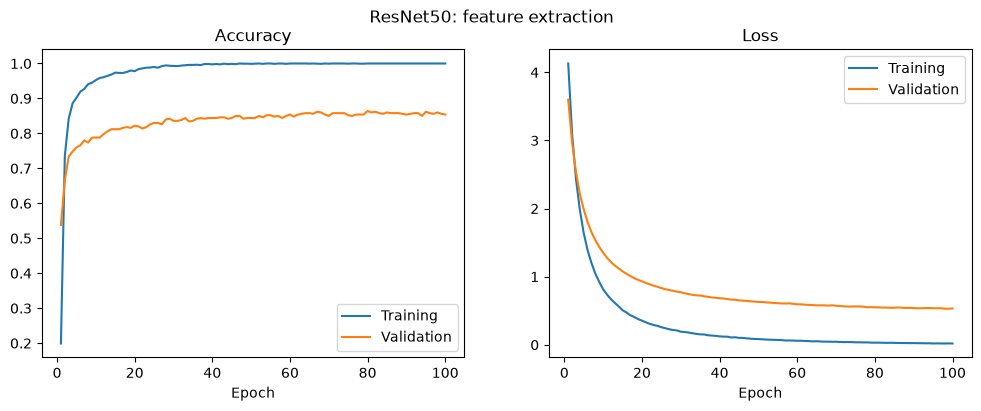

ResNet50: feature extraction
  Train accuracy:      1.0
  Validation accuracy: 0.856
  Test accuracy:       0.862
  Test loss:           0.541


In [88]:
plot_history(history_resnet_fe, "ResNet50: feature extraction")
evaluate_model(resnet_fe, "ResNet50: feature extraction")

### Stage 2: fine-tuning (also train the last block, `layer4`)

We start from the stage 1 weights, unfreeze the last block so it can adapt to butterflies, and use a **much smaller learning rate** (0.0001) so we gently adjust the pretrained knowledge instead of destroying it.

In [90]:
resnet_ft = build_resnet50()
load_saved_weights(resnet_ft, "resnet50_feature_extraction")   # start from stage 1

# Unfreeze the last block of ResNet50 (resnet_ft[1] is the ResNet itself)
for parameter in resnet_ft[1].layer4.parameters():
    parameter.requires_grad = True

count_parameters(resnet_ft)

Total parameters:     23712932
Parameters training:  15169636
Parameters frozen:    8543296


In [91]:
history_resnet_ft = train_model(resnet_ft, "resnet50_finetuned", train_loader_aug, learning_rate=0.0001, epochs=20)

Epoch 1 | train loss 0.106 acc 0.982 | val loss 0.7 acc 0.832 | time 15.39 sec
Epoch 2 | train loss 0.009 acc 1.0 | val loss 0.655 acc 0.842 | time 15.04 sec
Epoch 3 | train loss 0.007 acc 0.999 | val loss 0.639 acc 0.842 | time 14.97 sec
Epoch 4 | train loss 0.004 acc 1.0 | val loss 0.649 acc 0.848 | time 15.01 sec
Epoch 5 | train loss 0.003 acc 1.0 | val loss 0.632 acc 0.846 | time 15.1 sec
Epoch 6 | train loss 0.002 acc 1.0 | val loss 0.612 acc 0.854 | time 15.06 sec
Epoch 7 | train loss 0.003 acc 1.0 | val loss 0.618 acc 0.856 | time 15.13 sec
Epoch 8 | train loss 0.002 acc 1.0 | val loss 0.611 acc 0.858 | time 14.99 sec
Epoch 9 | train loss 0.001 acc 1.0 | val loss 0.591 acc 0.858 | time 15.04 sec
Epoch 10 | train loss 0.001 acc 1.0 | val loss 0.605 acc 0.868 | time 15.03 sec
Epoch 11 | train loss 0.001 acc 1.0 | val loss 0.595 acc 0.856 | time 14.97 sec
Epoch 12 | train loss 0.001 acc 1.0 | val loss 0.582 acc 0.866 | time 14.96 sec
Epoch 13 | train loss 0.001 acc 1.0 | val loss 0

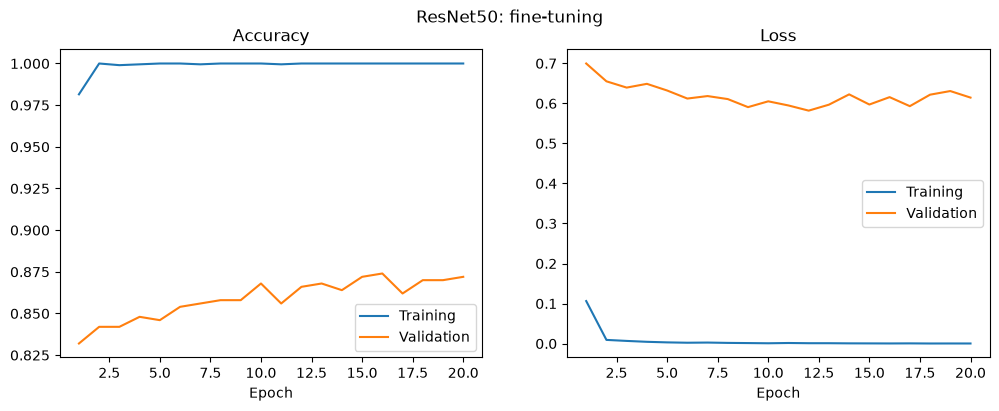

ResNet50: fine-tuned
  Train accuracy:      1.0
  Validation accuracy: 0.866
  Test accuracy:       0.902
  Test loss:           0.452


In [92]:
plot_history(history_resnet_ft, "ResNet50: fine-tuning")
evaluate_model(resnet_ft, "ResNet50: fine-tuned")

In [93]:
# Classification report for fine-tuned ResNet50
show_report(resnet_ft)

                           precision    recall  f1-score   support

                   ADONIS       0.56      1.00      0.71         5
AFRICAN GIANT SWALLOWTAIL       1.00      1.00      1.00         5
           AMERICAN SNOOT       0.80      0.80      0.80         5
                    AN 88       1.00      1.00      1.00         5
                  APPOLLO       1.00      1.00      1.00         5
     ARCIGERA FLOWER MOTH       1.00      1.00      1.00         5
                    ATALA       1.00      1.00      1.00         5
               ATLAS MOTH       1.00      1.00      1.00         5
 BANDED ORANGE HELICONIAN       1.00      1.00      1.00         5
           BANDED PEACOCK       1.00      0.80      0.89         5
        BANDED TIGER MOTH       1.00      1.00      1.00         5
            BECKERS WHITE       0.75      0.60      0.67         5
  BIRD CHERRY ERMINE MOTH       1.00      0.80      0.89         5
         BLACK HAIRSTREAK       1.00      1.00      1.00     

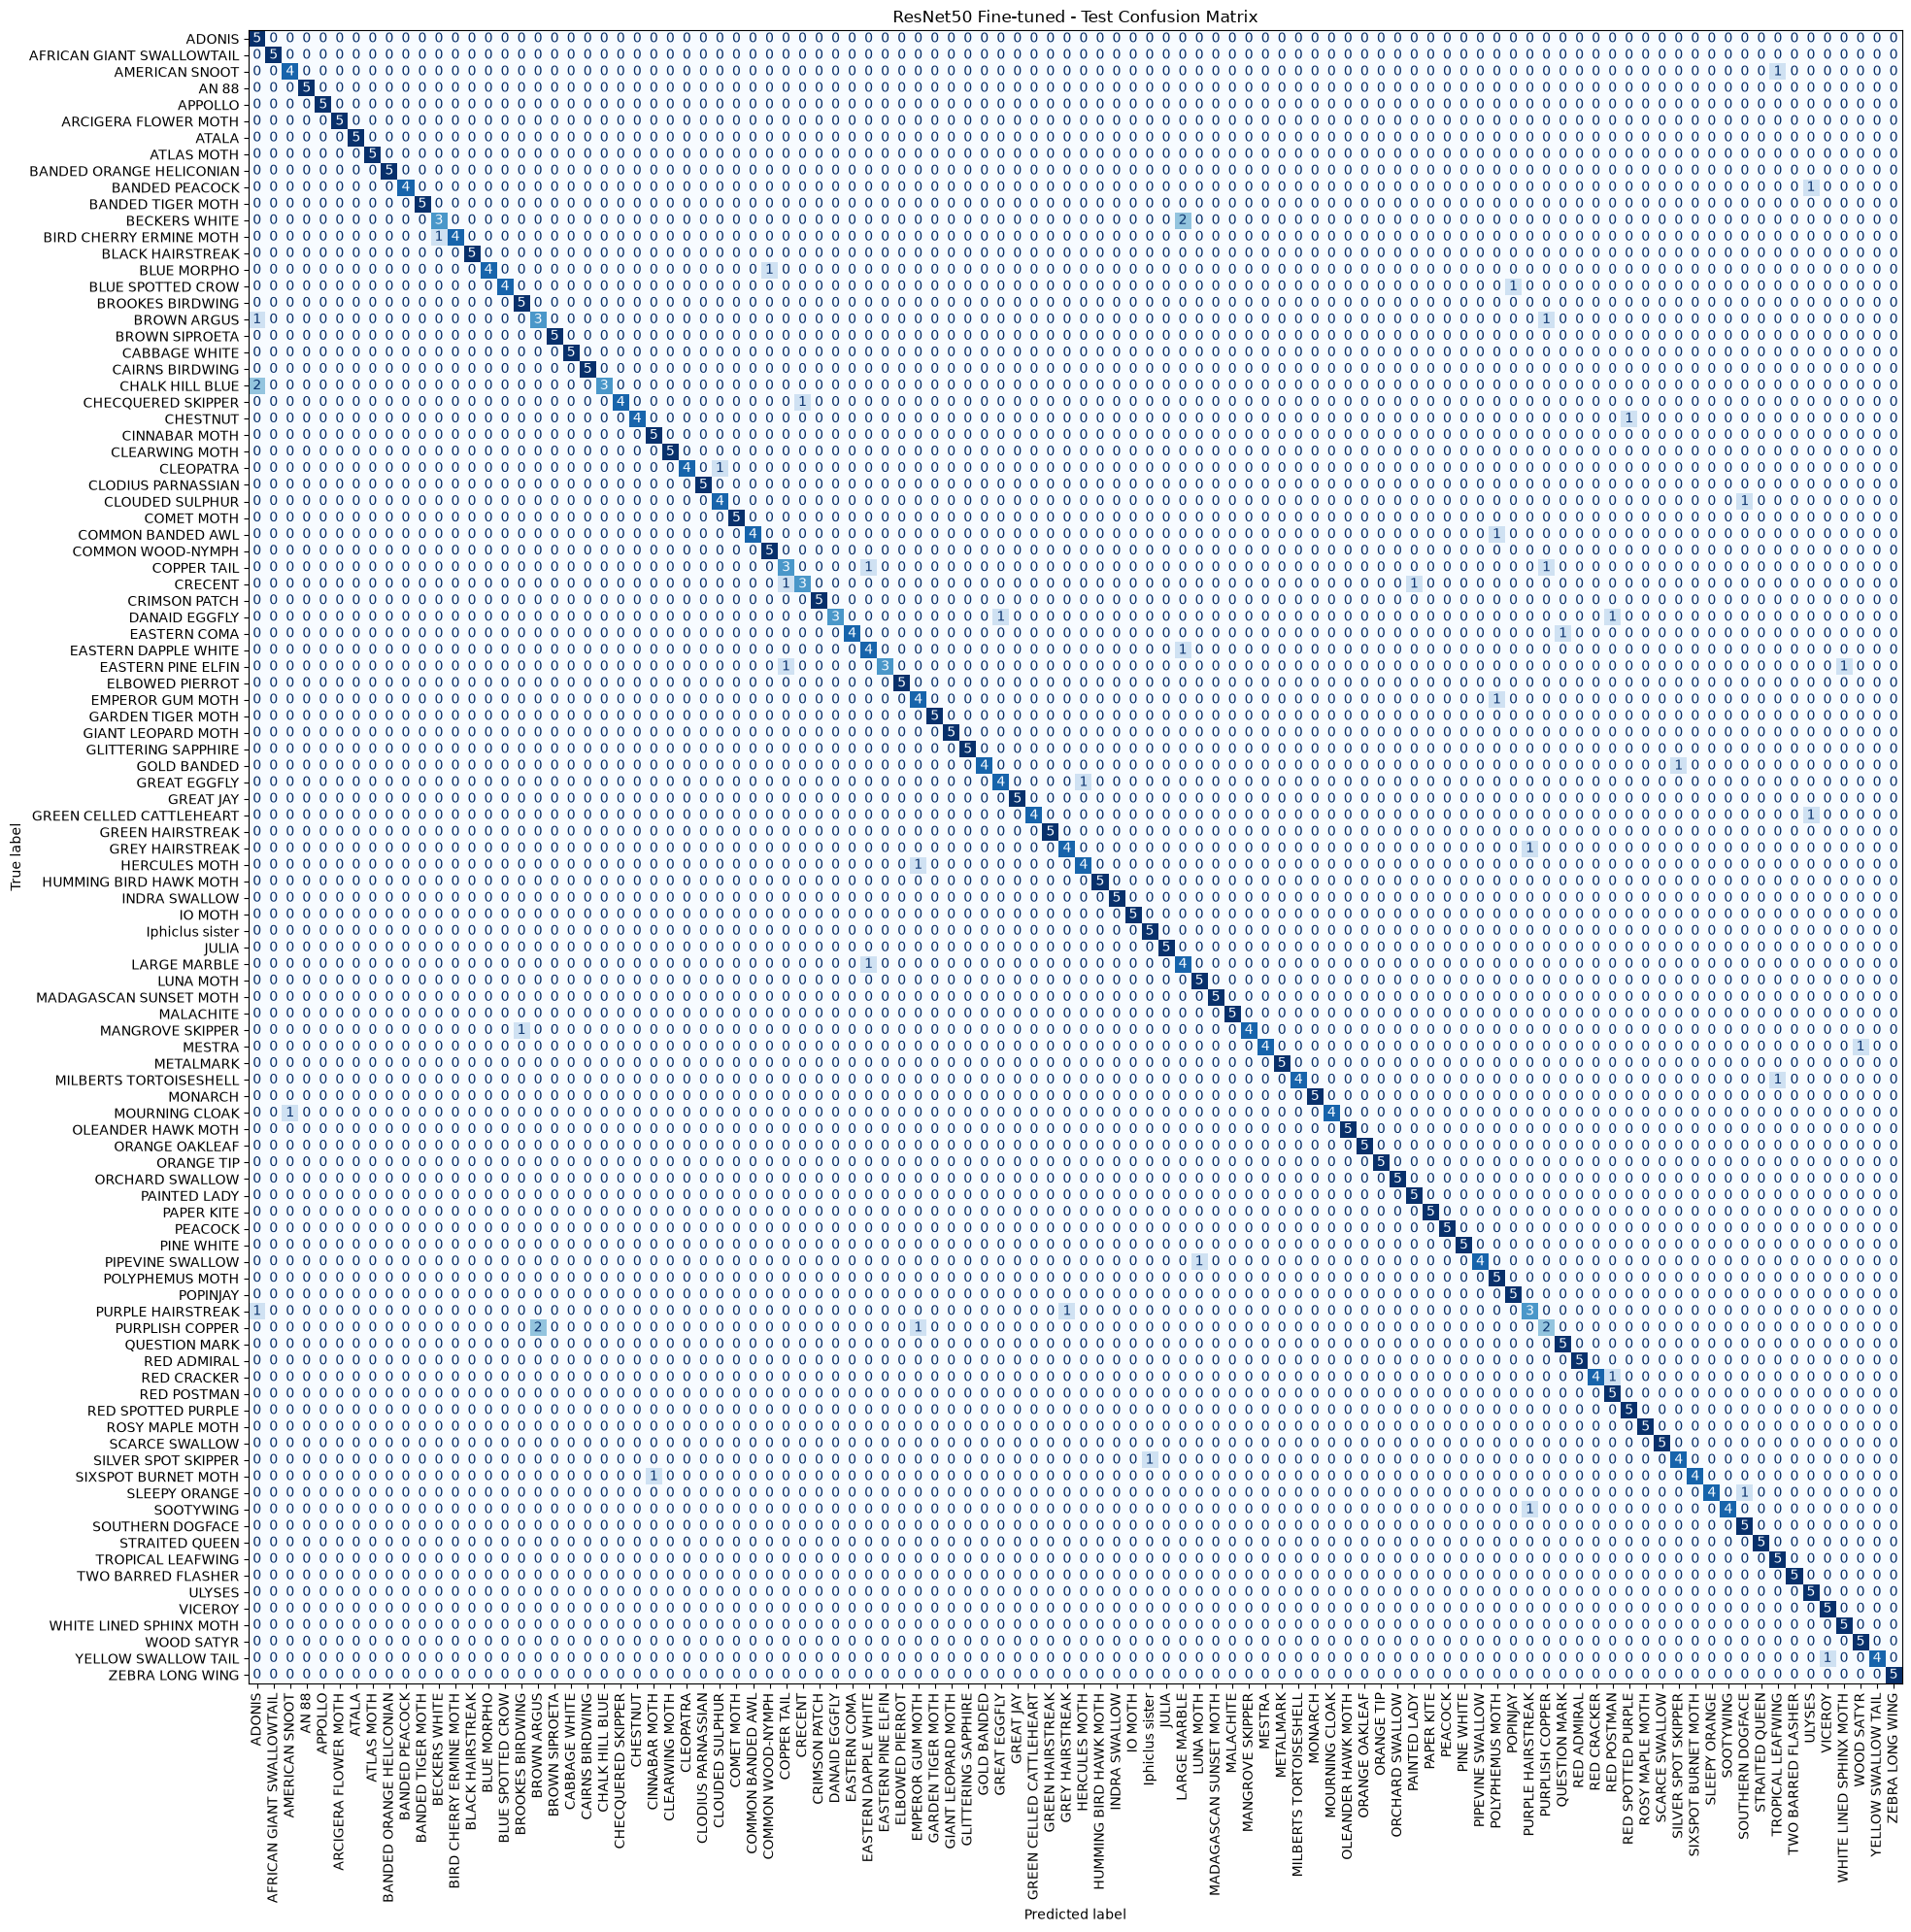

In [143]:
#Confusion matrix
show_cm(resnet_ft, "ResNet50 Fine-tuned")

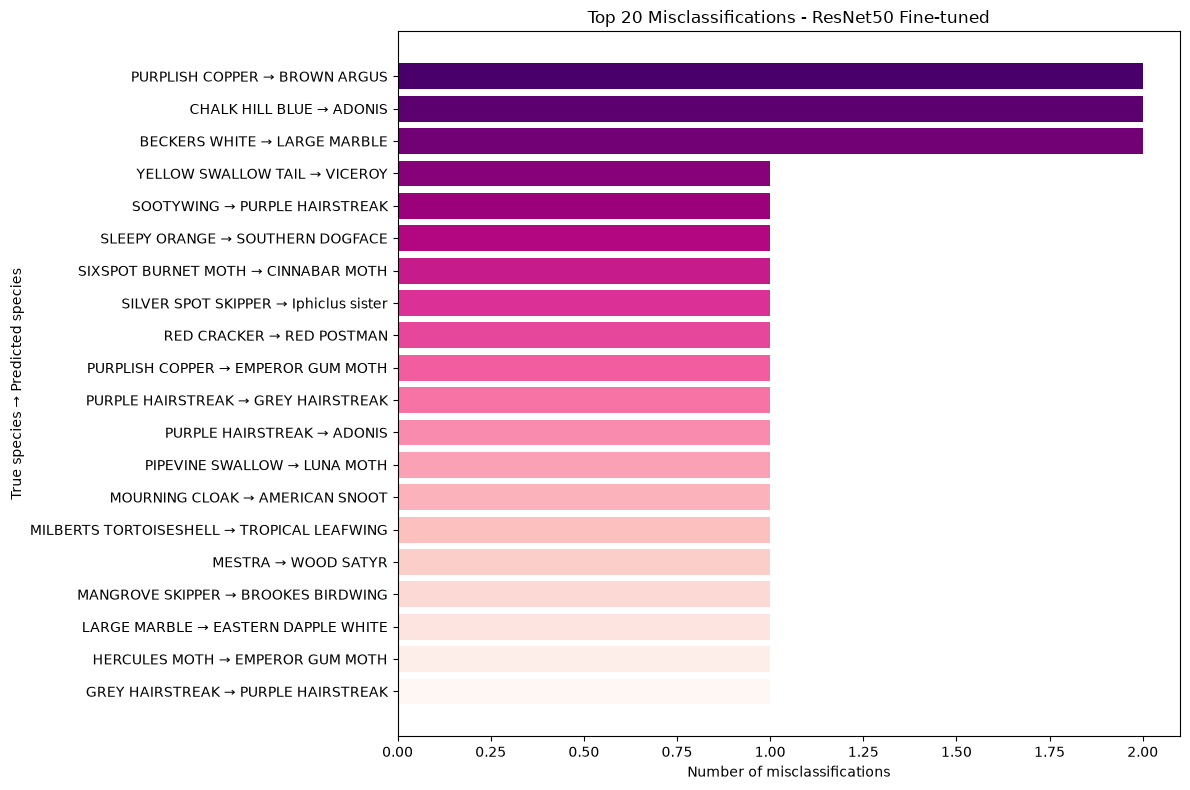

In [160]:
#Top mistakes bar plot
plot_top_misses(resnet_ft, "ResNet50 Fine-tuned")

## Model 2: EfficientNet-B0

EfficientNet-B0 is a much smaller and more efficient network (about 5 million weights, roughly 5 times fewer than ResNet50). It was designed to get high accuracy with fewer calculations.

### Stage 1: feature extraction

In [95]:
def build_efficientnet():
    backbone = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)

    # Freeze every pretrained weight
    for parameter in backbone.parameters():
        parameter.requires_grad = False

    # Replace the final layer (1000 ImageNet classes) with a new one for our species
    backbone.classifier[1] = nn.Linear(1280, num_classes)

    return nn.Sequential(ImageNetNormalize(), backbone)

effnet_fe = build_efficientnet()
count_parameters(effnet_fe)

Total parameters:     4135648
Parameters training:  128100
Parameters frozen:    4007548


In [96]:
history_effnet_fe = train_model(effnet_fe, "efficientnet_b0_feature_extraction", train_loader_aug, learning_rate=0.001)

Found a saved model for efficientnet_b0_feature_extraction - loading it (no training needed).


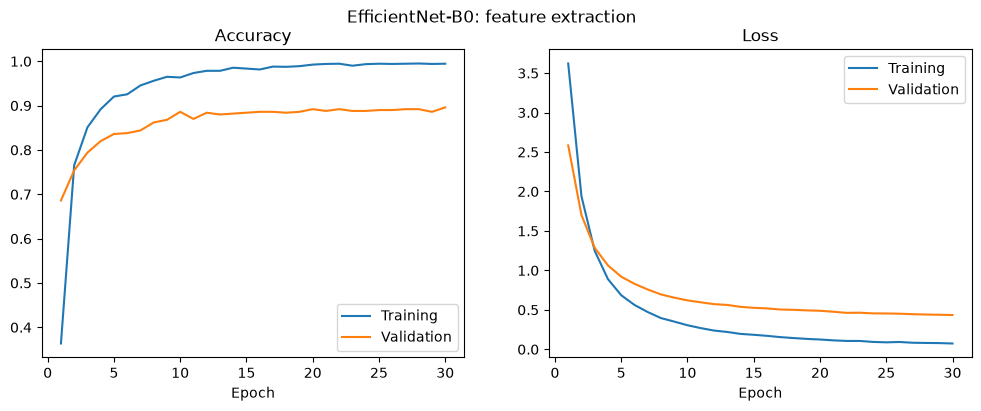

EfficientNet-B0: feature extraction
  Train accuracy:      0.998
  Validation accuracy: 0.896
  Test accuracy:       0.908
  Test loss:           0.392


In [97]:
plot_history(history_effnet_fe, "EfficientNet-B0: feature extraction")
evaluate_model(effnet_fe, "EfficientNet-B0: feature extraction")

### Stage 2: fine-tuning (also train the last 3 blocks)

In [99]:
effnet_ft = build_efficientnet()
load_saved_weights(effnet_ft, "efficientnet_b0_feature_extraction")   # start from stage 1

# Unfreeze the last 3 blocks of EfficientNet-B0 (effnet_ft[1] is the EfficientNet itself)
for block in effnet_ft[1].features[-3:]:
    for parameter in block.parameters():
        parameter.requires_grad = True

count_parameters(effnet_ft)

Total parameters:     4135648
Parameters training:  3283840
Parameters frozen:    851808


In [100]:
history_effnet_ft = train_model(effnet_ft, "efficientnet_b0_finetuned", train_loader_aug, learning_rate=0.0001, epochs=20)

Epoch 1 | train loss 0.432 acc 0.915 | val loss 0.465 acc 0.862 | time 9.48 sec
Epoch 2 | train loss 0.135 acc 0.977 | val loss 0.407 acc 0.878 | time 9.61 sec
Epoch 3 | train loss 0.079 acc 0.99 | val loss 0.376 acc 0.896 | time 9.25 sec
Epoch 4 | train loss 0.056 acc 0.996 | val loss 0.365 acc 0.904 | time 9.32 sec
Epoch 5 | train loss 0.039 acc 0.997 | val loss 0.356 acc 0.908 | time 9.32 sec
Epoch 6 | train loss 0.034 acc 0.996 | val loss 0.347 acc 0.908 | time 9.24 sec
Epoch 7 | train loss 0.03 acc 0.997 | val loss 0.344 acc 0.914 | time 9.26 sec
Epoch 8 | train loss 0.024 acc 0.999 | val loss 0.338 acc 0.92 | time 9.3 sec
Epoch 9 | train loss 0.025 acc 0.998 | val loss 0.326 acc 0.918 | time 9.47 sec
Epoch 10 | train loss 0.018 acc 0.999 | val loss 0.329 acc 0.92 | time 9.38 sec
Epoch 11 | train loss 0.015 acc 0.998 | val loss 0.338 acc 0.912 | time 9.73 sec
Epoch 12 | train loss 0.013 acc 1.0 | val loss 0.33 acc 0.918 | time 9.46 sec
Epoch 13 | train loss 0.012 acc 0.999 | val l

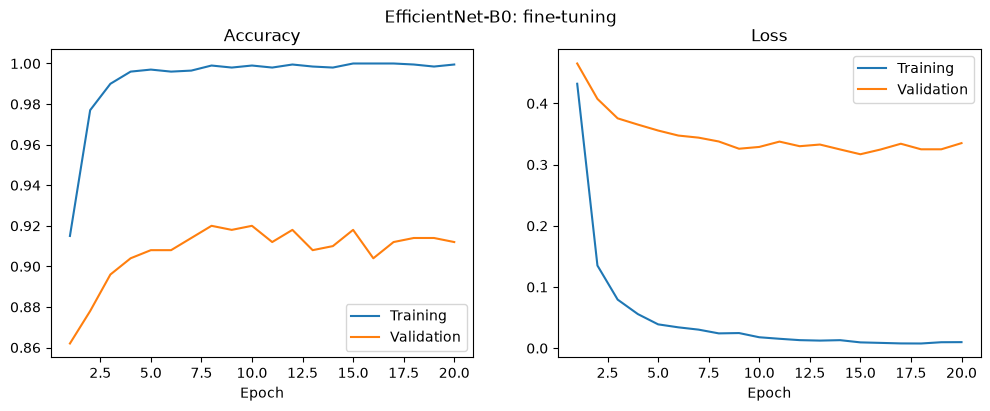

EfficientNet-B0: fine-tuned
  Train accuracy:      1.0
  Validation accuracy: 0.918
  Test accuracy:       0.928
  Test loss:           0.254


In [101]:
plot_history(history_effnet_ft, "EfficientNet-B0: fine-tuning")
evaluate_model(effnet_ft, "EfficientNet-B0: fine-tuned")

In [102]:
# Classification report for fine-tuned EfficientNet-B0
show_report(effnet_ft)

                           precision    recall  f1-score   support

                   ADONIS       0.56      1.00      0.71         5
AFRICAN GIANT SWALLOWTAIL       1.00      1.00      1.00         5
           AMERICAN SNOOT       1.00      0.80      0.89         5
                    AN 88       1.00      1.00      1.00         5
                  APPOLLO       0.83      1.00      0.91         5
     ARCIGERA FLOWER MOTH       1.00      1.00      1.00         5
                    ATALA       1.00      0.80      0.89         5
               ATLAS MOTH       1.00      1.00      1.00         5
 BANDED ORANGE HELICONIAN       1.00      1.00      1.00         5
           BANDED PEACOCK       0.83      1.00      0.91         5
        BANDED TIGER MOTH       1.00      1.00      1.00         5
            BECKERS WHITE       0.80      0.80      0.80         5
  BIRD CHERRY ERMINE MOTH       1.00      0.80      0.89         5
         BLACK HAIRSTREAK       1.00      1.00      1.00     

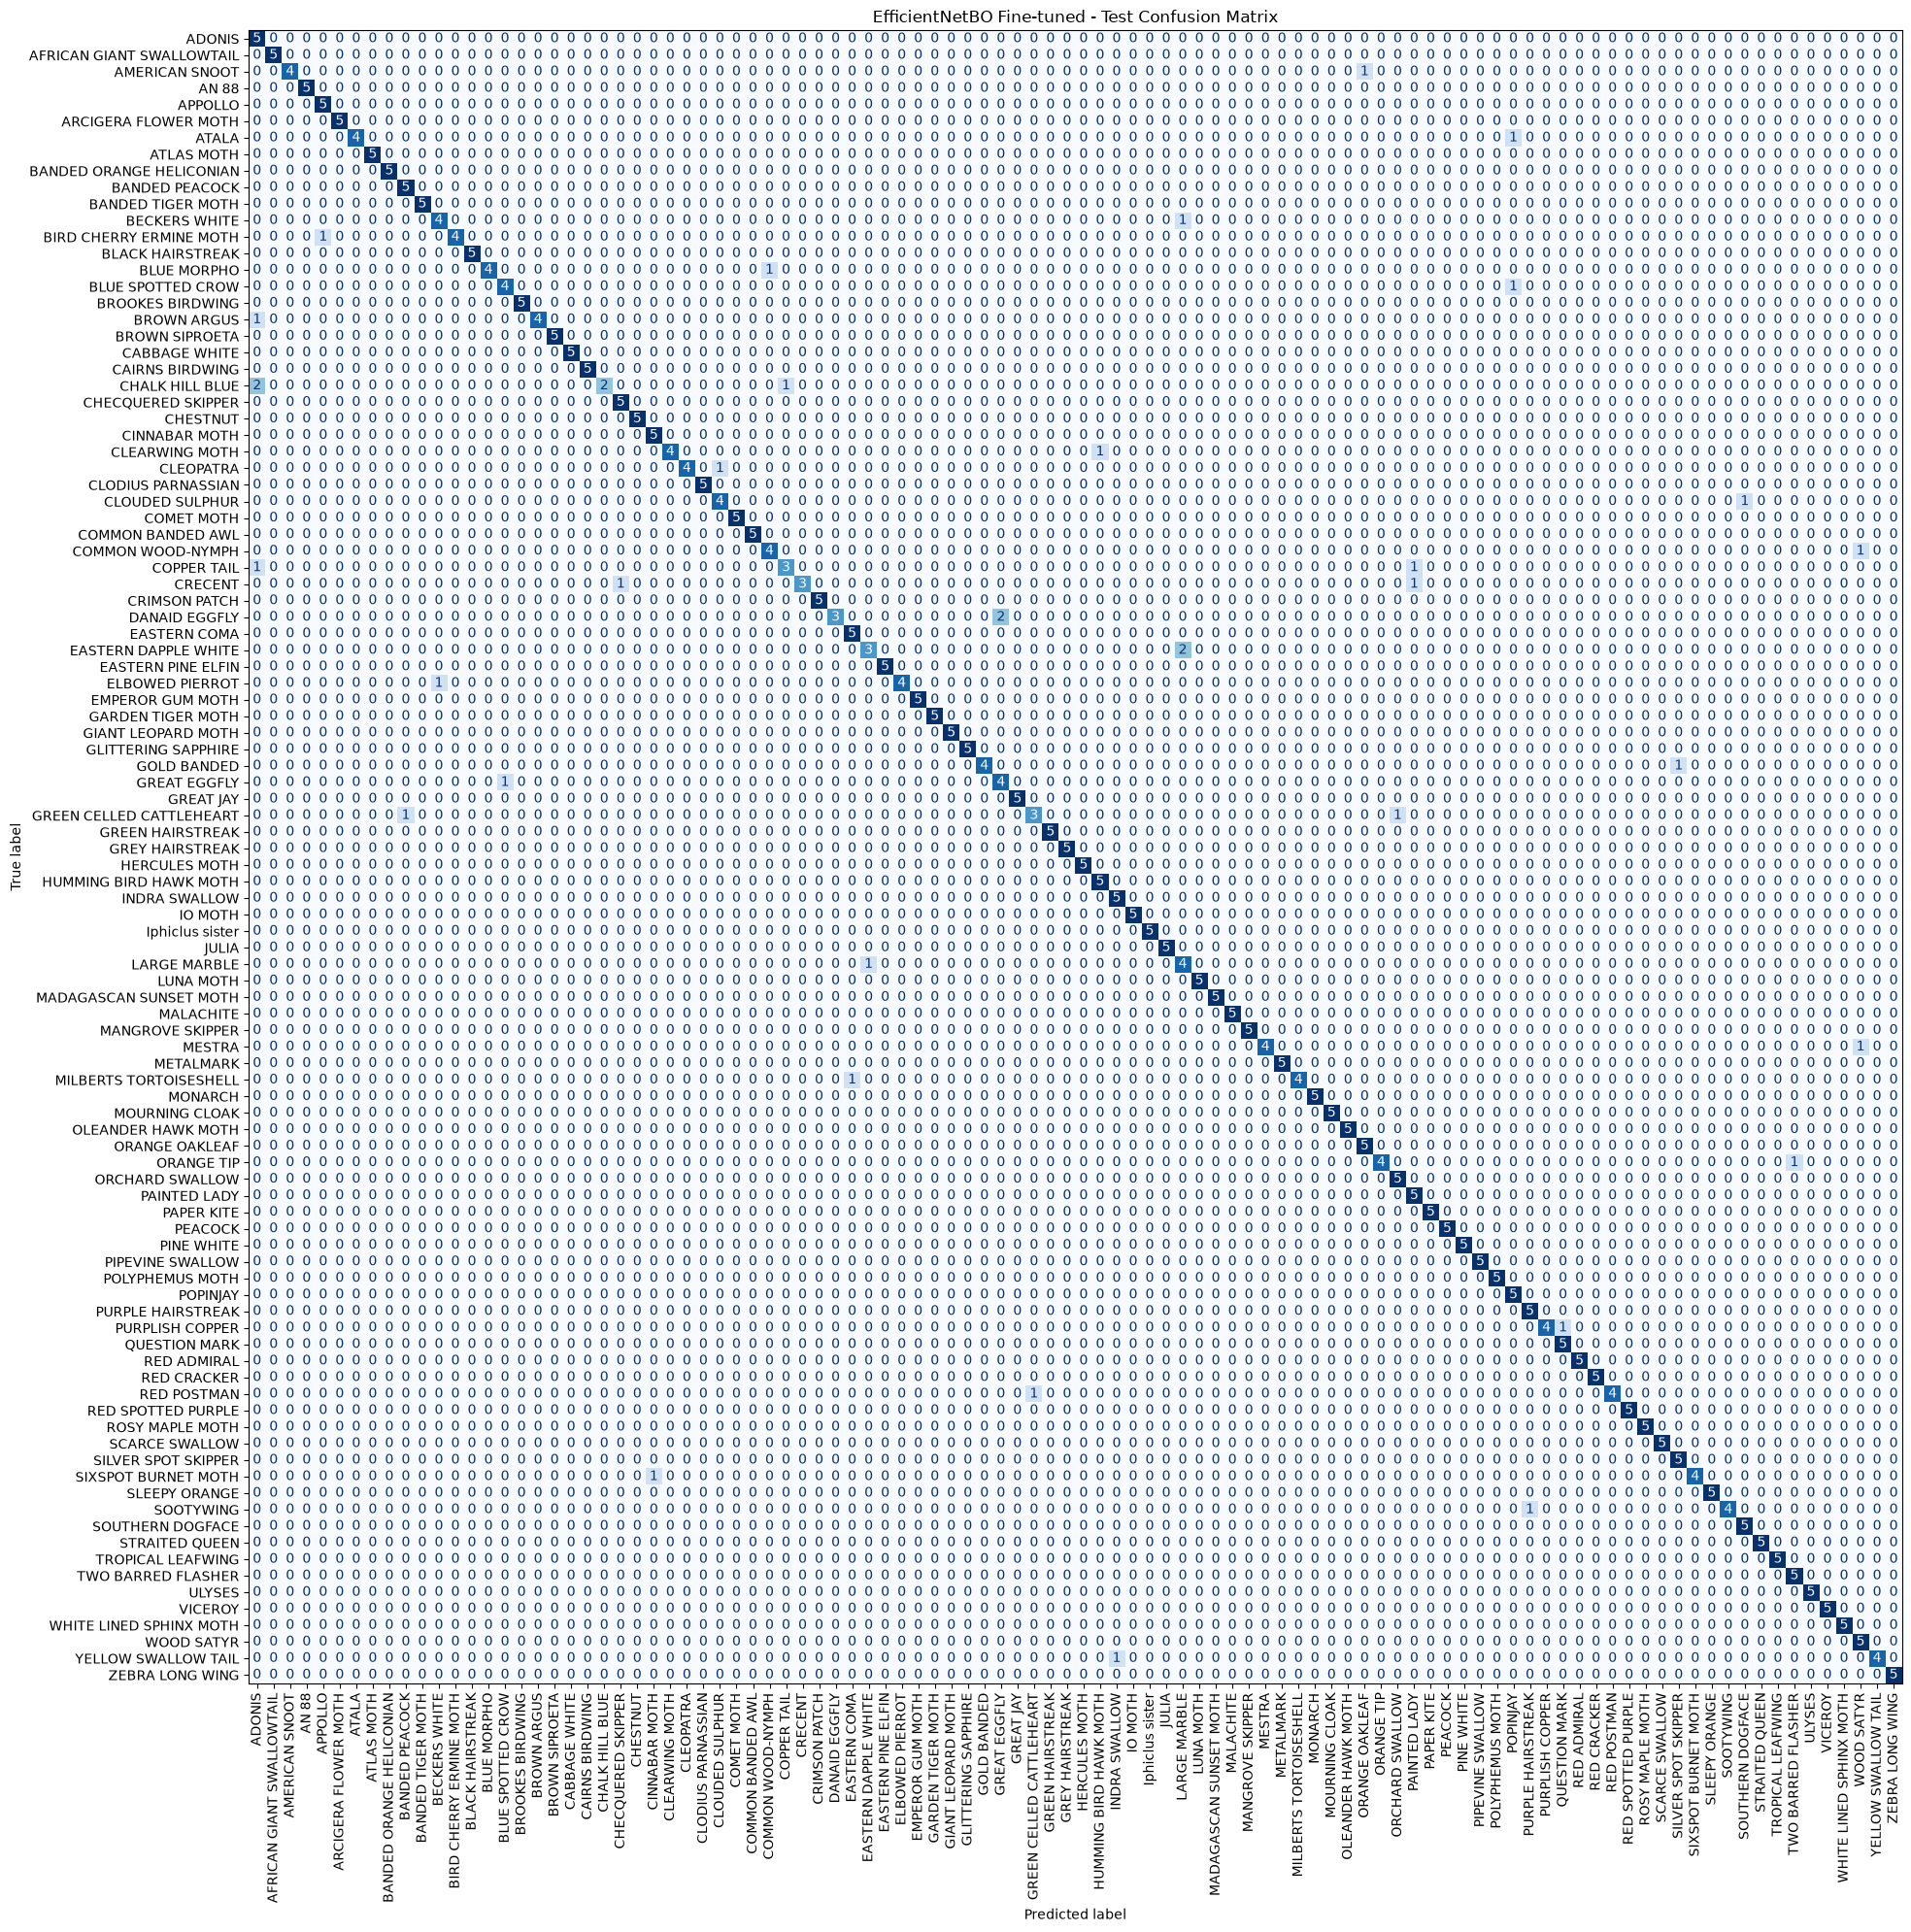

In [162]:
#Confusion Matrix
show_cm(effnet_ft, "EfficientNetBO Fine-tuned")

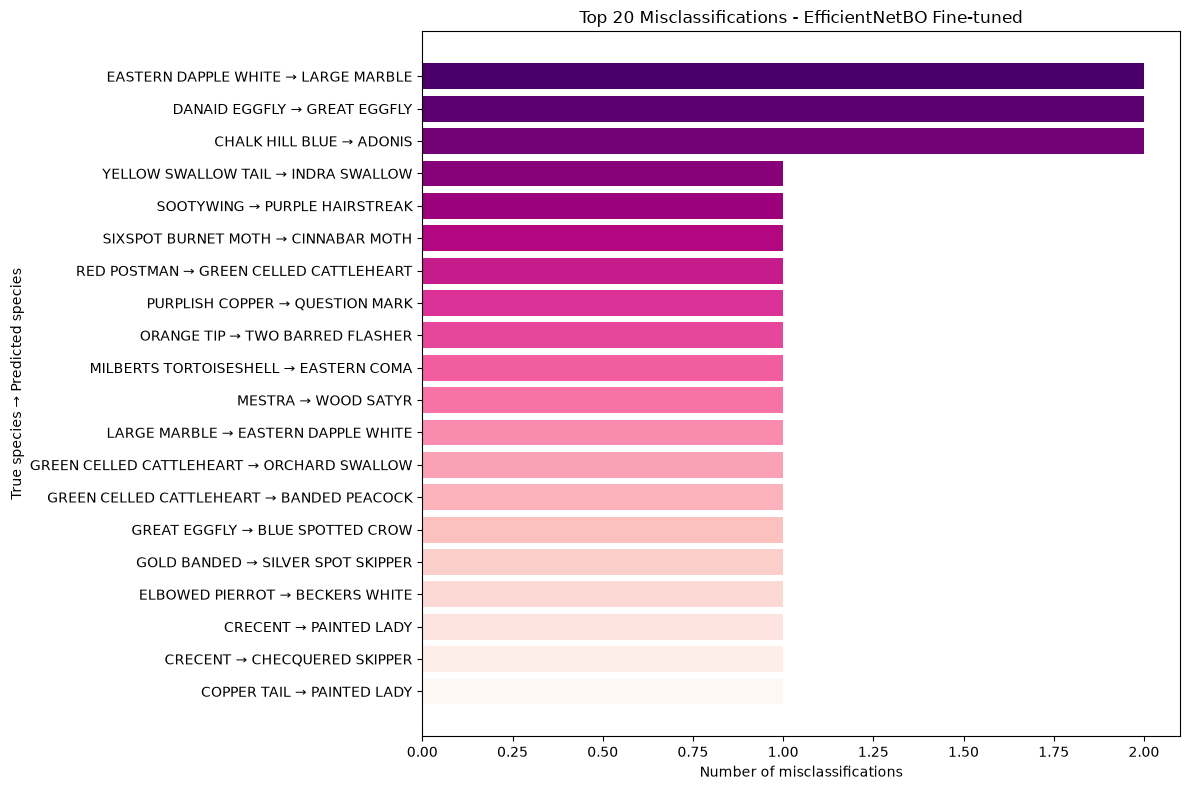

In [163]:
#Top mistakes bar plot
plot_top_misses(effnet_ft, "EfficientNetBO Fine-tuned")

## Compare transfer models with the CNN

In [123]:
#Combine all saved results into 1 place
history_results = []

for history_file in glob.glob("checkpoints/*_history.json"):

    name = os.path.basename(history_file).replace("_history.json", "")

    with open(history_file) as file:
        history = json.load(file)

    best_epoch = history["val_loss"].index(min(history["val_loss"]))

    history_results.append({"model": name,
                            "best_epoch": best_epoch + 1,
                            "train_acc": history["accuracy"][best_epoch],
                            "val_acc": history["val_accuracy"][best_epoch],
                            "val_loss": history["val_loss"][best_epoch],
                            "training_time_min": history.get("training_time_min")})

history_table = pd.DataFrame(history_results)

history_table["train_minus_val"] = (history_table["train_acc"] - history_table["val_acc"])

history_table = history_table.round(3)

display(history_table)

,model,best_epoch,train_acc,val_acc,val_loss,training_time_min,train_minus_val
0,resnet50_finetuned,12,1.000,0.866,0.582,5.05,0.134
1,resnet50_feature_extraction,99,1.000,0.856,0.529,20.56,0.144
2,cnn4_lr0.0001_bs64,21,0.992,0.670,1.528,10.44,0.322
3,cnn_v1_raw_pixels,3,0.450,0.242,3.399,3.54,0.208
4,cnn4_lr0.001_bs64,17,0.990,0.664,1.456,8.51,0.326
5,cnn4_lr0.0003_bs64,28,0.994,0.676,1.498,9.16,0.318
6,cnn_v3_augmentation,26,0.822,0.418,2.550,7.42,0.404
7,cnn4_lr0.0003_bs16,15,0.960,0.646,1.572,8.62,0.314
8,cnn4_lr0.001_bs16,28,0.990,0.698,1.490,8.67,0.292
9,cnn_v2_baseline,9,0.665,0.358,3.071,3.55,0.307


In [125]:
# Select the best version of each model based on validation loss

# Best tuned CNN4
best_cnn = history_table[
history_table["model"].str.startswith("cnn4_lr")].sort_values("val_loss").iloc[0]

# Best ResNet50
best_resnet = history_table[
    history_table["model"].str.contains("resnet50", case=False)
    ].sort_values("val_loss").iloc[0]

# Best EfficientNet
best_efficientnet = history_table[
    history_table["model"].str.contains("efficientnet", case=False)
    ].sort_values("val_loss").iloc[0]

best_comparison = pd.DataFrame([best_cnn, best_resnet, best_efficientnet]).copy()

best_comparison["model"] = ["Best CNN4", "Best ResNet50", "Best EfficientNet"]

display(best_comparison)

,model,best_epoch,train_acc,val_acc,val_loss,training_time_min,train_minus_val
4,Best CNN4,17,0.99,0.664,1.456,8.51,0.326
1,Best ResNet50,99,1.00,0.856,0.529,20.56,0.144
15,Best EfficientNet,15,1.00,0.918,0.317,3.14,0.082


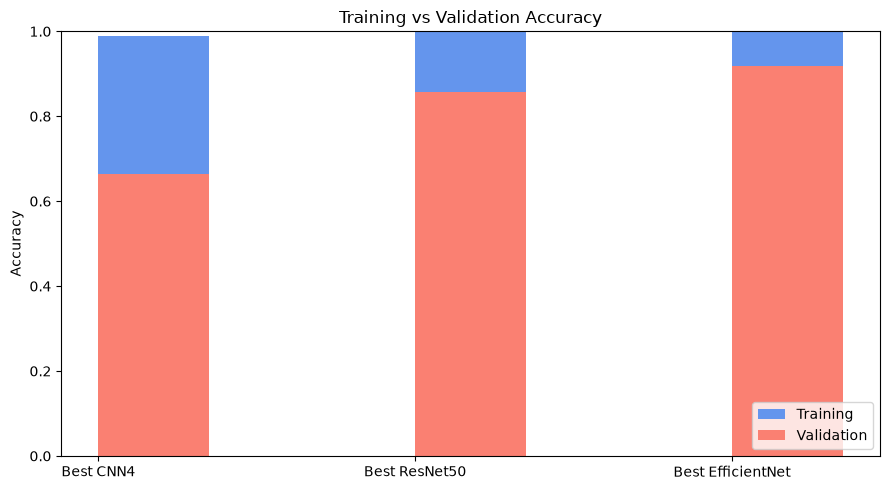

In [146]:
# train/valid accuracy comparison graph
x = np.arange(len(best_comparison))
width = 0.35

plt.figure(figsize=(9, 5))

train_bars = plt.bar(x + width/2, best_comparison["train_acc"], width, 
                   label="Training", color="cornflowerblue")
val_bars = plt.bar(x + width/2, best_comparison["val_acc"], width, 
                   label="Validation", color="salmon")
plt.xticks(x, best_comparison["model"])
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## Next (Part 3)

Final evaluation: confusion matrices and error analysis for the best models, a look at the mistakes, and an optional hybrid (combining ResNet50 and EfficientNet-B0).